# 1. Breed standards and the flock data

**Author:** Mahdi Dadgar

This notebook shows the published standards the data are built on, and what the synthetic flock records look like.
The data come from `python -m src.generate_data`; the method is described in `docs/methodology.md`.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import FIGURES_DIR, FLOCKS_FILE, QUALITY_FILE, REPORTS_DIR, TRUTH_DIR, WEEKLY_FILE

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 10})
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
GREEN, GREY, BLUE, ORANGE = "#2E7D32", "#757575", "#1565C0", "#E65100"
STRAIN_COL = {"Lohmann Brown-Classic": ORANGE, "Hy-Line W-80": BLUE}
pd.set_option("display.width", 140)
from src.standards import strain_standard, requirements
flocks = pd.read_csv(FLOCKS_FILE)
weekly = pd.read_csv(WEEKLY_FILE)
quality = pd.read_csv(QUALITY_FILE)
print(f"{len(flocks)} flocks, {flocks.farm_id.nunique()} farms, {len(weekly)} weekly records, {len(quality)} egg quality samples")

622 flocks, 52 farms, 38448 weekly records, 8259 egg quality samples


## Published standards

Hen-day production and egg weight come from the Lohmann Brown-Classic management guide and the Hy-Line W-80 performance standards
(midpoint of the published range). Haugh units come from the Hy-Line guides, and shell breaking strength by age from
Benavides-Reyes et al. (2021). The grey points are the published values; the lines between them are my interpolation.

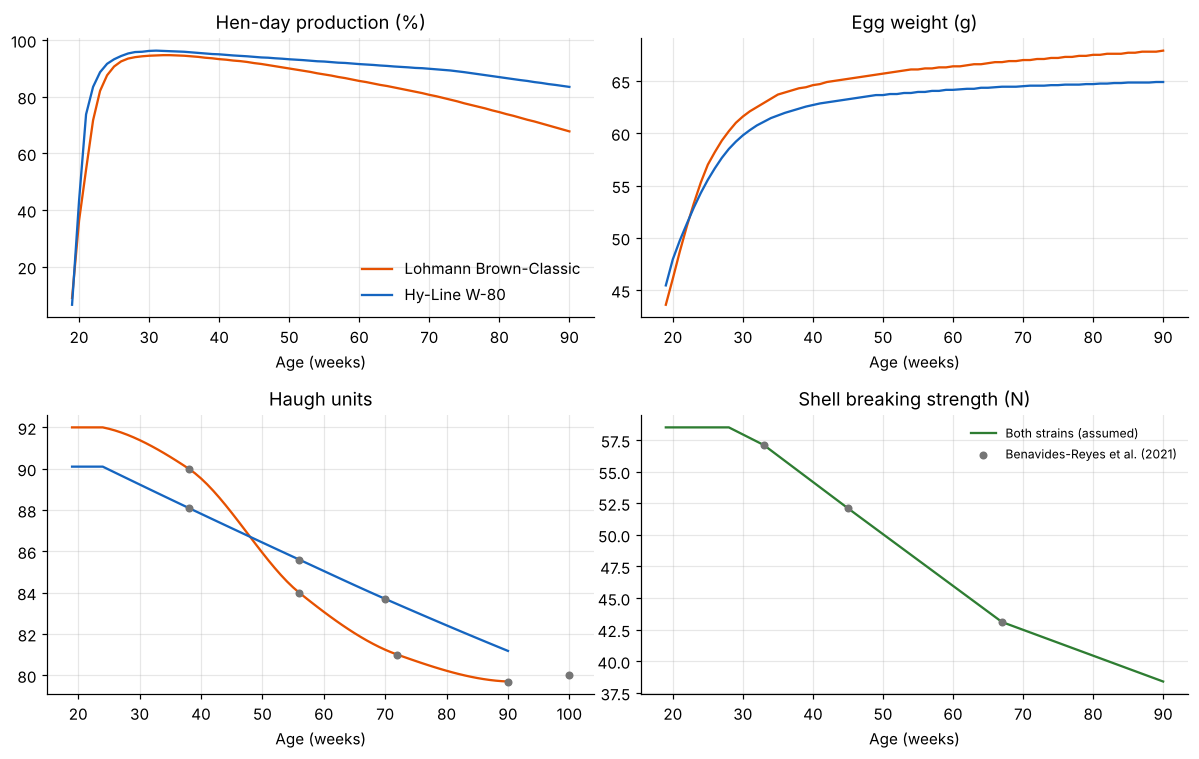

In [2]:
from src.standards import _tables
eq = _tables()[3]
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for s, c in STRAIN_COL.items():
    std = strain_standard(s)
    ax[0, 0].plot(std.index, std.hen_day_pct, color=c, label=s)
    ax[0, 1].plot(std.index, std.egg_weight_g, color=c, label=s)
    ax[1, 0].plot(std.index, std.haugh_units, color=c, label=s)
ax[1, 1].plot(std.index, std.breaking_strength_n, color=GREEN, label="Both strains (assumed)")
for strain_name, c in [("Hy-Line Brown", ORANGE), ("Hy-Line W-80", BLUE)]:
    p = eq[(eq.measure == "haugh_units") & (eq.strain == strain_name)]
    ax[1, 0].scatter(p.week, p.value, color=GREY, zorder=3, s=18)
p = eq[eq.measure == "breaking_strength"]
ax[1, 1].scatter(p.week, p.value, color=GREY, zorder=3, s=18, label="Benavides-Reyes et al. (2021)")
for a, t in zip(ax.flat, ["Hen-day production (%)", "Egg weight (g)", "Haugh units", "Shell breaking strength (N)"]):
    a.set_title(t); a.set_xlabel("Age (weeks)")
ax[0, 0].legend(frameon=False); ax[1, 1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIGURES_DIR / "01_breed_standards.png", bbox_inches="tight"); plt.show()

The daily nutrient targets are the Lohmann Brown-Classic recommendations for three phases. I interpolate between the phase
midpoints so the requirement changes smoothly with age, and use the same daily targets for both strains.

In [3]:
requirements().loc[[19, 35, 50, 60, 70, 80, 90]].round(3)

,crude_protein_g,calcium_g,available_p_g,dig_lysine_g,dig_met_cys_g,linoleic_acid_g
week,,,,,,
19,18.500,4.100,0.420,0.820,0.740,2.000
35,18.490,4.106,0.420,0.820,0.740,1.992
50,18.196,4.282,0.408,0.808,0.728,1.757
60,18.000,4.400,0.400,0.800,0.720,1.600
70,17.500,4.450,0.390,0.785,0.705,1.450
80,17.000,4.500,0.380,0.770,0.690,1.300
90,17.000,4.500,0.380,0.770,0.690,1.300


## The flocks

Each farm has one housing system and climate, and mostly keeps one strain. Diets differ between farms because each farm follows its own
nutrition policy, and about one flock in five follows a new supplier's policy.

In [4]:
flocks.groupby(["strain", "housing", "climate_zone"]).size().unstack(fill_value=0)

climate_zone                         temperate  warm
strain                housing                       
Hy-Line W-80          barn                  88    46
                      enriched cage         48    11
                      free range            99    28
Lohmann Brown-Classic barn                  93    49
                      enriched cage         24    40
                      free range            60    36

In [5]:
from src.features import planning_features
feats = planning_features(flocks)
ratios = feats[["r_lys", "r_mc", "r_ca", "r_avp"]].rename(columns={
    "r_lys": "Dig. lysine", "r_mc": "Dig. Met+Cys", "r_ca": "Calcium", "r_avp": "Available P"})
ratios.describe(percentiles=[0.05, 0.5, 0.95]).round(3)

,Dig. lysine,Dig. Met+Cys,Calcium,Available P
count,40235.000,40235.000,40235.000,40235.000
mean,0.994,0.993,1.004,0.985
std,0.054,0.058,0.071,0.098
min,0.841,0.825,0.816,0.768
5%,0.900,0.895,0.897,0.840
50%,0.995,0.993,1.000,0.968
95%,1.090,1.093,1.121,1.160
max,1.174,1.204,1.200,1.220


Supply is expressed as expected daily intake divided by the daily requirement. Most flocks get between 90 % and 110 % of the
amino acid target, with a tail below 90 %.

## What the records look like

Field flocks rarely reach the breed standard. In these data the average flock peaks four to five points below the standard,
and the gap widens late in lay, mostly in barn and free-range flocks.

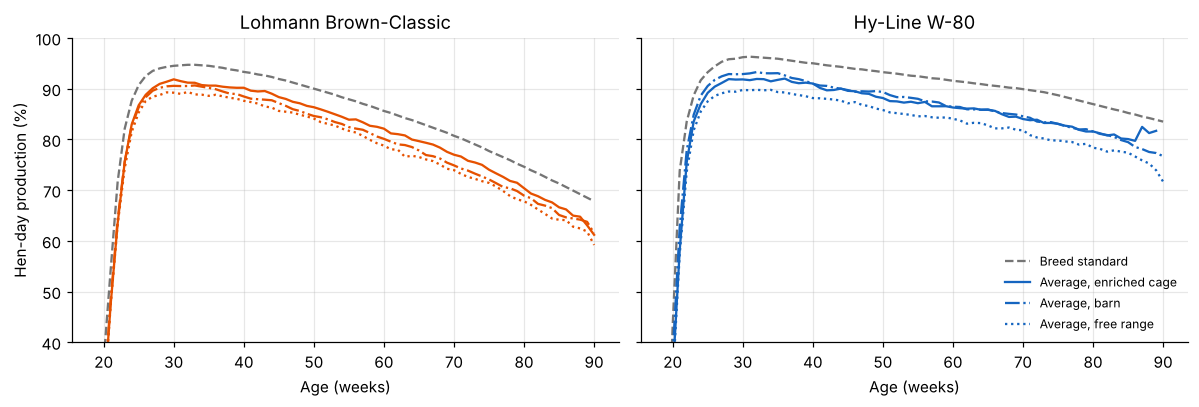

In [6]:
w = weekly.merge(flocks[["flock_id", "strain", "housing"]], on="flock_id")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a, (s, c) in zip(ax, STRAIN_COL.items()):
    std = strain_standard(s)
    a.plot(std.index, std.hen_day_pct, color=GREY, ls="--", label="Breed standard")
    for h, ls in [("enriched cage", "-"), ("barn", "-."), ("free range", ":")]:
        g = w[(w.strain == s) & (w.housing == h)].groupby("age_wk").hen_day_pct.mean()
        a.plot(g.index, g.values, color=c, ls=ls, label=f"Average, {h}")
    a.set_title(s); a.set_xlabel("Age (weeks)"); a.set_ylim(40, 100)
ax[0].set_ylabel("Hen-day production (%)"); ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIGURES_DIR / "01_field_vs_standard.png", bbox_inches="tight"); plt.show()

Individual flocks are noisier. Some have a disease episode: production drops within a week, recovers over the next few weeks, and
often does not get all the way back. Respiratory episodes also weaken the shell and lower Haugh units. The episodes are not
recorded in the data, as is often the case on farms; they are kept in `data/truth/` for validation only.

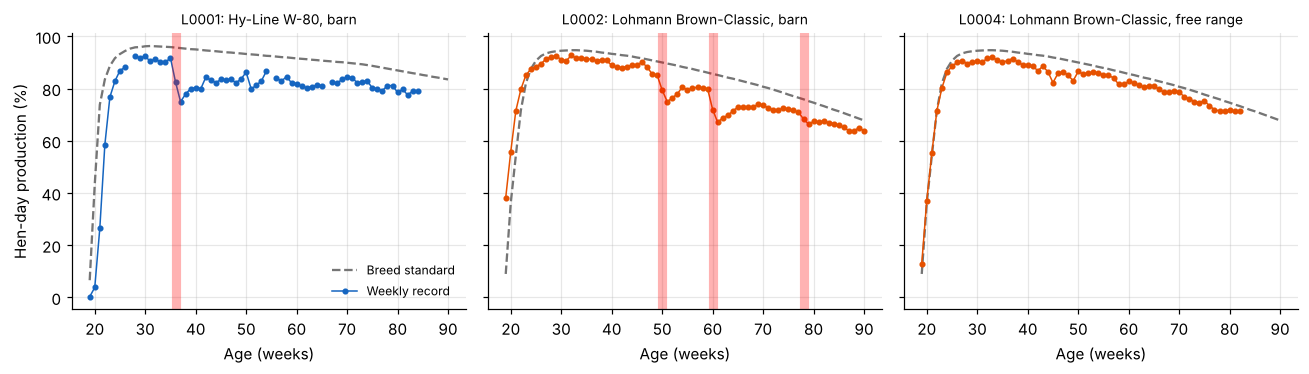

Red bands: start of a disease episode (from the truth files, not in the records)


In [7]:
events = pd.read_csv(TRUTH_DIR / "disease_events.csv")
big = events[(events.depth > 0.10) & events.start_wk.between(35, 60)].flock_id.unique()[:2]
ids = list(big) + list(flocks[~flocks.flock_id.isin(events.flock_id)].flock_id[:1])
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for a, fid in zip(ax, ids):
    fl = flocks.set_index("flock_id").loc[fid]
    g = weekly[weekly.flock_id == fid]
    std = strain_standard(fl.strain)
    a.plot(std.index, std.hen_day_pct, color=GREY, ls="--", label="Breed standard")
    a.plot(g.age_wk, g.hen_day_pct, color=STRAIN_COL[fl.strain], marker=".", lw=1, label="Weekly record")
    for e in events[events.flock_id == fid].itertuples():
        a.axvline(e.start_wk, color="red", alpha=0.3, lw=6)
    a.set_title(f"{fid}: {fl.strain}, {fl.housing}", fontsize=9); a.set_xlabel("Age (weeks)")
ax[0].set_ylabel("Hen-day production (%)"); ax[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIGURES_DIR / "01_example_flocks.png", bbox_inches="tight"); plt.show()
print("Red bands: start of a disease episode (from the truth files, not in the records)")

## Missing values

Records are missing the way they would be on a farm: a week not entered, a feed intake not measured. The models handle missing
values in the inputs; rows with a missing target are left out of training for that target.

In [8]:
(weekly.isna().mean() * 100).round(1).to_frame("% missing")

,% missing
flock_id,0.0
farm_id,0.0
age_wk,0.0
week_start,0.0
house_temp_max_c,1.9
hen_day_pct,2.0
feed_intake_g,5.0
egg_weight_g,4.1
mortality_pct,1.1
